#A Machine Learning Framework for Online Shopper Intent Prediction, Customer Segmentation and Anomaly Detection
An end-to-end machine learning pipeline on the UCI Online Shoppers Purchasing Intention data.

| Step | Work |
|---|---|
| 1 | Load data, encode, clean |
| 2 | EDA, class balance, correlation heatmap |
| 3| Classification (Logistic Regression, Decision Tree, Random Forest, XGBoost, SVM, KNN) with Stratified 5-Fold CV |
|4 | PCA + K-Means + Silhouette |
|5| Isolation Forest anomaly detection |
|6|feature importance |
| 7 | Predict on new sessions + save model |

Importing Functions

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.model_selection import cross_validate, cross_val_score, cross_val_predict
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.metrics import silhouette_score
from xgboost import XGBClassifier


* Data Loading & Preprocessing
* Remove duplicate rows (so the same session is not in both train and test).
* Month -> number (Jan=1,Feb = 2 ... Dec = 12).
*  VisitorType -> one-hot columns.
* Weekend and Revenue -> 0/1.
* Scaling is done inside the models (pipelines)

In [49]:
data =pd.read_csv("online_shoppers_intention.csv")
print("Shape:", data.shape)
display(data)
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

data = data.drop_duplicates().reset_index(drop=True)
raw_data = data.copy()

data["Weekend"] = data["Weekend"].astype(int)
data["Revenue"] = data["Revenue"].astype(int)

month_map = {"Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4, "May": 5, "June": 6,
             "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}
data["Month"] = data["Month"].map(month_map)

visitor_types = sorted(data["VisitorType"].unique())
data = pd.get_dummies(data, columns=["VisitorType"], dtype=int)

X = data.drop("Revenue", axis=1)
y = data["Revenue"]
print("\nAfter cleaning:", X.shape)
print("Columns:", list(X.columns))


Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


Missing values: 0
Duplicate rows: 125

After cleaning: (12205, 19)
Columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend', 'VisitorType_New_Visitor', 'VisitorType_Other', 'VisitorType_Returning_Visitor']


In [50]:
print("======Dataset after preprocessing======")
display(data)

======Dataset after preprocessing======


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,2,1,1,1,1,0,0,0,0,1
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,2,2,2,1,2,0,0,0,0,1
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,2,4,1,9,3,0,0,0,0,1
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,2,3,2,2,4,0,0,0,0,1
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,2,3,3,1,4,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12200,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,12,4,6,1,1,1,0,0,0,1
12201,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,11,3,2,1,8,1,0,0,0,1
12202,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,11,3,2,1,13,1,0,0,0,1
12203,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,11,2,2,3,11,0,0,0,0,1


EDA & Correlation Heatmap

Non-buyers (0): 10297 (84.4%)
Buyers     (1): 1908 (15.6%)
The data is imbalanced, so accuracy alone is not enough. We also check recall, F1 and ROC-AUC.


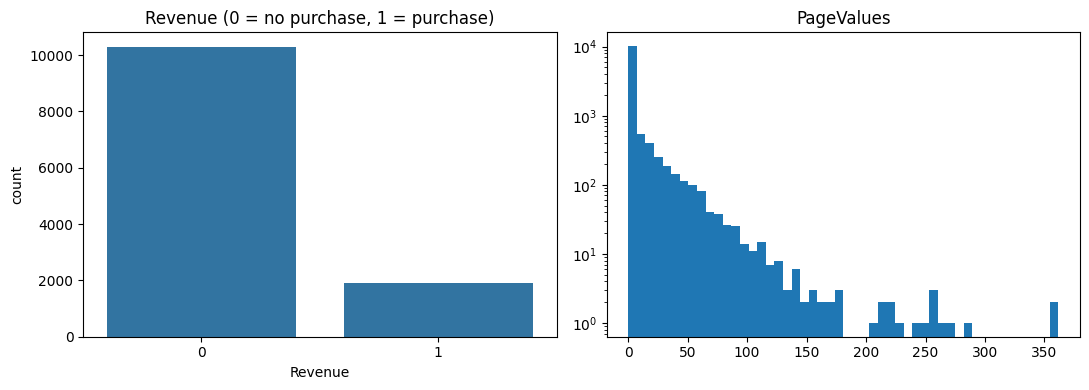

                                  mean      std  min     50%       max
Administrative                    2.34     3.33  0.0    1.00     27.00
Administrative_Duration          81.65   177.49  0.0    9.00   3398.75
Informational                     0.51     1.28  0.0    0.00     24.00
Informational_Duration           34.83   141.42  0.0    0.00   2549.38
ProductRelated                   32.05    44.59  0.0   18.00    705.00
ProductRelated_Duration        1206.98  1919.60  0.0  608.94  63973.52
BounceRates                       0.02     0.05  0.0    0.00      0.20
ExitRates                         0.04     0.05  0.0    0.02      0.20
PageValues                        5.95    18.65  0.0    0.00    361.76
SpecialDay                        0.06     0.20  0.0    0.00      1.00
Month                             7.67     3.39  2.0    8.00     12.00
OperatingSystems                  2.12     0.91  1.0    2.00      8.00
Browser                           2.36     1.71  1.0    2.00     13.00
Region

In [51]:
counts = y.value_counts()
percent = y.value_counts(normalize=True) * 100
print("Non-buyers (0):", counts[0], f"({percent[0]:.1f}%)")
print("Buyers     (1):", counts[1], f"({percent[1]:.1f}%)")
print("The data is imbalanced, so accuracy alone is not enough. We also check recall, F1 and ROC-AUC.")

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
sns.countplot(x=y)
plt.title("Revenue (0 = no purchase, 1 = purchase)")
plt.subplot(1, 2, 2)
plt.hist(X["PageValues"], bins=50)
plt.yscale("log")
plt.title("PageValues")
plt.tight_layout()
plt.show()

print(data.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

Correlation with Revenue:
PageValues                       0.492
ProductRelated                   0.156
ProductRelated_Duration          0.150
Administrative                   0.136
Month                            0.126
VisitorType_New_Visitor          0.103
Informational                    0.094
Administrative_Duration          0.092
Informational_Duration           0.069
Weekend                          0.028
Browser                          0.024
VisitorType_Other                0.009
TrafficType                     -0.006
Region                          -0.013
OperatingSystems                -0.015
SpecialDay                      -0.084
VisitorType_Returning_Visitor   -0.103
BounceRates                     -0.145
ExitRates                       -0.204
Name: Revenue, dtype: float64


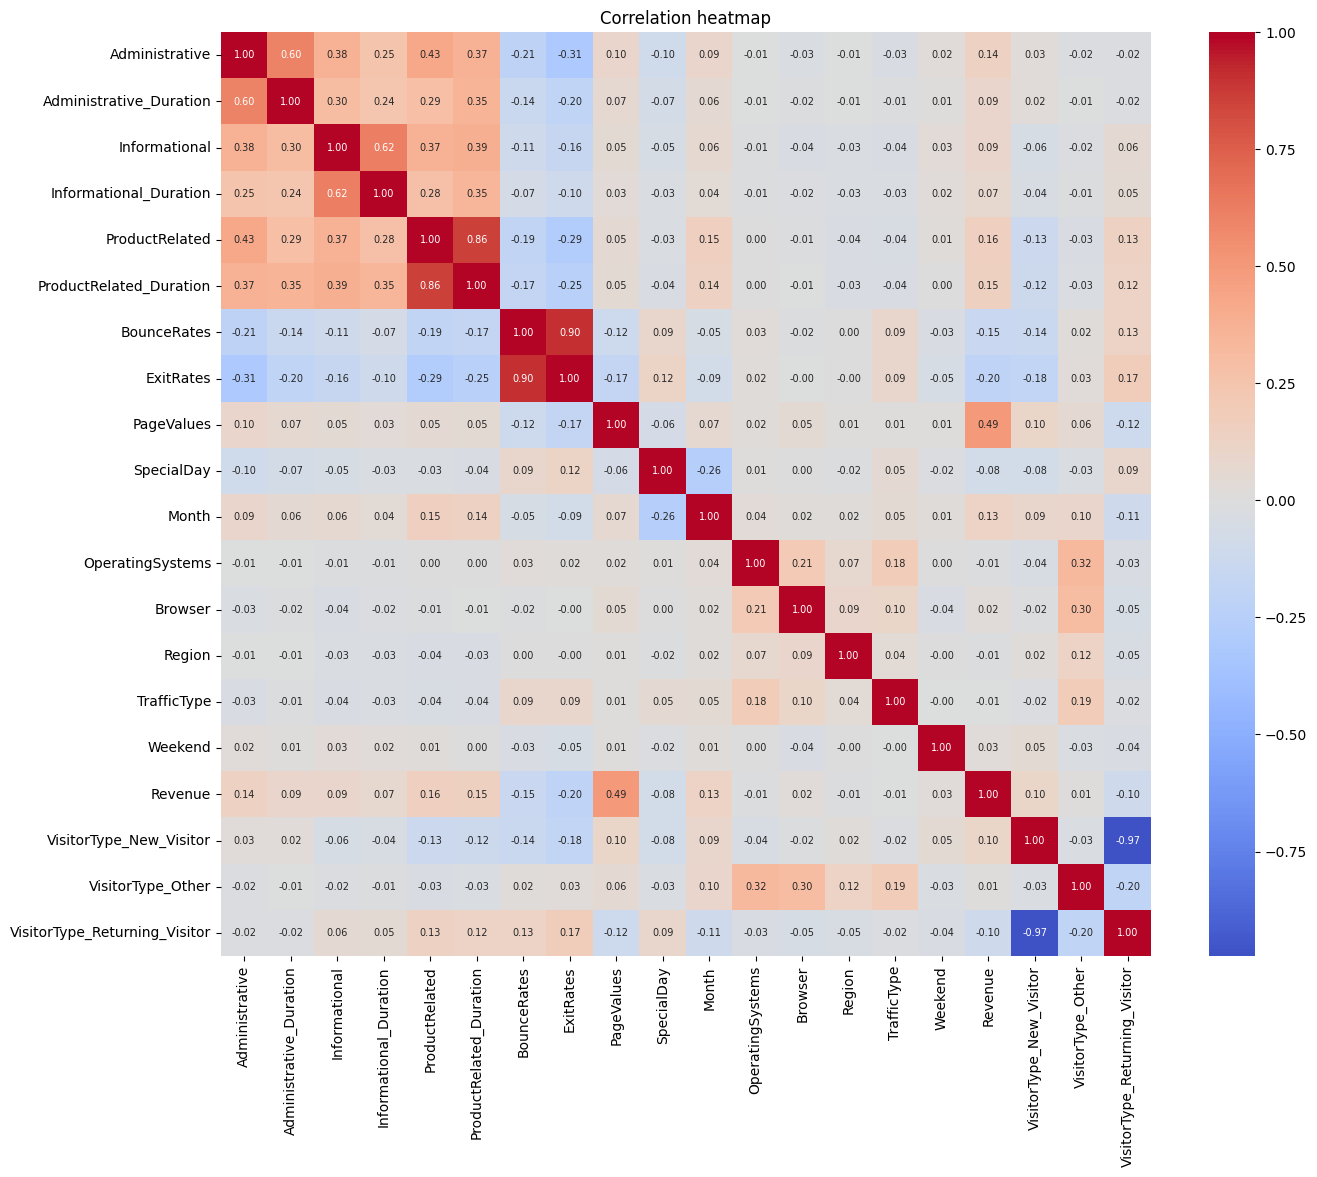

In [52]:
corr = data.corr()
print("Correlation with Revenue:")
print(corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3))

plt.figure(figsize=(15, 12))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

Classification (Intent Prediction)
1. Split 80% train / 20% test (stratified). The test set is used only at the end.
2. Compare models using Stratified 5-Fold CV on the train set.
3. Handle imbalance with `class_weight="balanced"` (and `scale_pos_weight` for XGBoost).
4. Tune `C` of Logistic Regression (L2), the number of neighbours `K` of KNN, and XGBoost.
5. Pick the decision threshold using cross-validation predictions (not the test set).

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    # Logistic Regression uses L2 regularization by default
    "Logistic Regression": make_pipeline(StandardScaler(),LogisticRegression(C=1, class_weight="balanced", max_iter=3000)),

    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20,class_weight="balanced", random_state=42),

    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,class_weight="balanced", random_state=42, n_jobs=-1),

    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,scale_pos_weight=ratio, random_state=42),

    "SVM": make_pipeline(StandardScaler(), SVC(class_weight="balanced", random_state=42)),

    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),     # KNN has no class_weight option
}

Train: (9764, 19)  Test: (2441, 19)


In [54]:
# tune C of Logistic Regression (L2 strength)
grid = GridSearchCV(models["Logistic Regression"],
                    {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                    scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
models["Logistic Regression"] = grid.best_estimator_
print("Best C for Logistic Regression:", grid.best_params_, " AUC:", round(grid.best_score_, 4))

# tune K (number of neighbours) of KNN
knn_grid = GridSearchCV(models["KNN"], {"kneighborsclassifier__n_neighbors": [11, 21, 31, 51, 75, 101]},scoring="roc_auc", cv=cv, n_jobs=-1)
knn_grid.fit(X_train, y_train)
models["KNN"] = knn_grid.best_estimator_
print("Best K for KNN:", knn_grid.best_params_, " AUC:", round(knn_grid.best_score_, 4))

# tune XGBoost
xgb_params = {"n_estimators": [100, 200, 300, 500],
              "max_depth": [2, 3, 4, 5],
              "learning_rate": [0.02, 0.05, 0.1],
              "subsample": [0.7, 0.8, 1.0],
              "colsample_bytree": [0.6, 0.8, 1.0],
              "min_child_weight": [1, 3, 5]}
search = RandomizedSearchCV(models["XGBoost"], xgb_params, n_iter=15,
                            scoring="roc_auc", cv=cv, n_jobs=-1, random_state=42)
search.fit(X_train, y_train)
models["XGBoost"] = search.best_estimator_
print("Best XGBoost params:", search.best_params_, " AUC:", round(search.best_score_, 4))

Best C for Logistic Regression: {'logisticregression__C': 100}  AUC: 0.8929
Best K for KNN: {'kneighborsclassifier__n_neighbors': 75}  AUC: 0.8511
Best XGBoost params: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 1.0}  AUC: 0.9314


In [55]:
# Stratified 5-Fold cross-validation for all models
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
cv_table = {}
auc_scores = {}

for name, model in models.items():
    result = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics, n_jobs=-1)
    row = {}
    for m in metrics:
        scores = result["test_" + m]
        row[m] = f"{scores.mean():.3f} +- {scores.std():.3f}"
    cv_table[name] = row
    auc_scores[name] = result["test_roc_auc"].mean()

print("STRATIFIED 5-FOLD CV RESULTS (mean +- std)")
print(pd.DataFrame(cv_table).T.to_string())

best_name = max([n for n in auc_scores if n != "SVM"], key=auc_scores.get)
print("\nBest model by CV ROC-AUC:", best_name)

STRATIFIED 5-FOLD CV RESULTS (mean +- std)
                           accuracy       precision          recall              f1         roc_auc average_precision
Logistic Regression  0.867 +- 0.011  0.557 +- 0.029  0.733 +- 0.028  0.633 +- 0.028  0.893 +- 0.011    0.640 +- 0.022
Decision Tree        0.862 +- 0.011  0.539 +- 0.024  0.835 +- 0.023  0.655 +- 0.020  0.919 +- 0.009    0.691 +- 0.023
Random Forest        0.874 +- 0.006  0.570 +- 0.015  0.803 +- 0.028  0.667 +- 0.012  0.927 +- 0.004    0.737 +- 0.019
XGBoost              0.863 +- 0.007  0.539 +- 0.014  0.838 +- 0.021  0.656 +- 0.014  0.931 +- 0.006    0.750 +- 0.021
SVM                  0.867 +- 0.006  0.555 +- 0.016  0.745 +- 0.022  0.636 +- 0.017  0.891 +- 0.007    0.639 +- 0.021
KNN                  0.871 +- 0.003  0.810 +- 0.035  0.226 +- 0.022  0.353 +- 0.027  0.851 +- 0.013    0.573 +- 0.025

Best model by CV ROC-AUC: XGBoost


In [56]:
# choose the threshold using cross-validation predictions on the train set
cv_prob = cross_val_predict(models[best_name], X_train, y_train, cv=cv,
                            method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, cv_prob)
f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
best_threshold = thresholds[np.argmax(f1_values)]
print(f"Best threshold for {best_name}: {best_threshold:.3f}")
print(f"CV F1 at 0.5 = {f1_score(y_train, cv_prob >= 0.5):.3f}, at best threshold = {f1_values.max():.3f}")

Best threshold for XGBoost: 0.698
CV F1 at 0.5 = 0.656, at best threshold = 0.694


In [57]:
# final test on the 20% test data
results = []
test_pred = {}
test_score = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    if name == "SVM":
        score = model.decision_function(X_test)
    else:
        score = model.predict_proba(X_test)[:, 1]
    test_pred[name] = pred
    test_score[name] = score
    results.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                    recall_score(y_test, pred), f1_score(y_test, pred),
                    roc_auc_score(y_test, score), average_precision_score(y_test, score)])

results = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall","F1", "ROC-AUC", "PR-AUC"]).set_index("Model")
print("TEST SET RESULTS")
print(results.round(4).to_string())

# best model with the tuned threshold
new_pred = (test_score[best_name] >= best_threshold).astype(int)
print(f"\n{best_name} with threshold {best_threshold:.3f}:")
print(f"Precision {precision_score(y_test, new_pred):.3f}, Recall {recall_score(y_test, new_pred):.3f}, "
      f"F1 {f1_score(y_test, new_pred):.3f}, Accuracy {accuracy_score(y_test, new_pred):.3f}")

TEST SET RESULTS
                     Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
Model                                                                    
Logistic Regression    0.8714     0.5656  0.7670  0.6511   0.9043  0.6561
Decision Tree          0.8669     0.5489  0.8377  0.6632   0.9268  0.6908
Random Forest          0.8726     0.5635  0.8246  0.6695   0.9322  0.7405
XGBoost                0.8656     0.5444  0.8665  0.6687   0.9379  0.7574
SVM                    0.8624     0.5441  0.7435  0.6283   0.8954  0.6290
KNN                    0.8718     0.8053  0.2382  0.3677   0.8660  0.5931

XGBoost with threshold 0.698:
Precision 0.643, Recall 0.741, F1 0.689, Accuracy 0.895


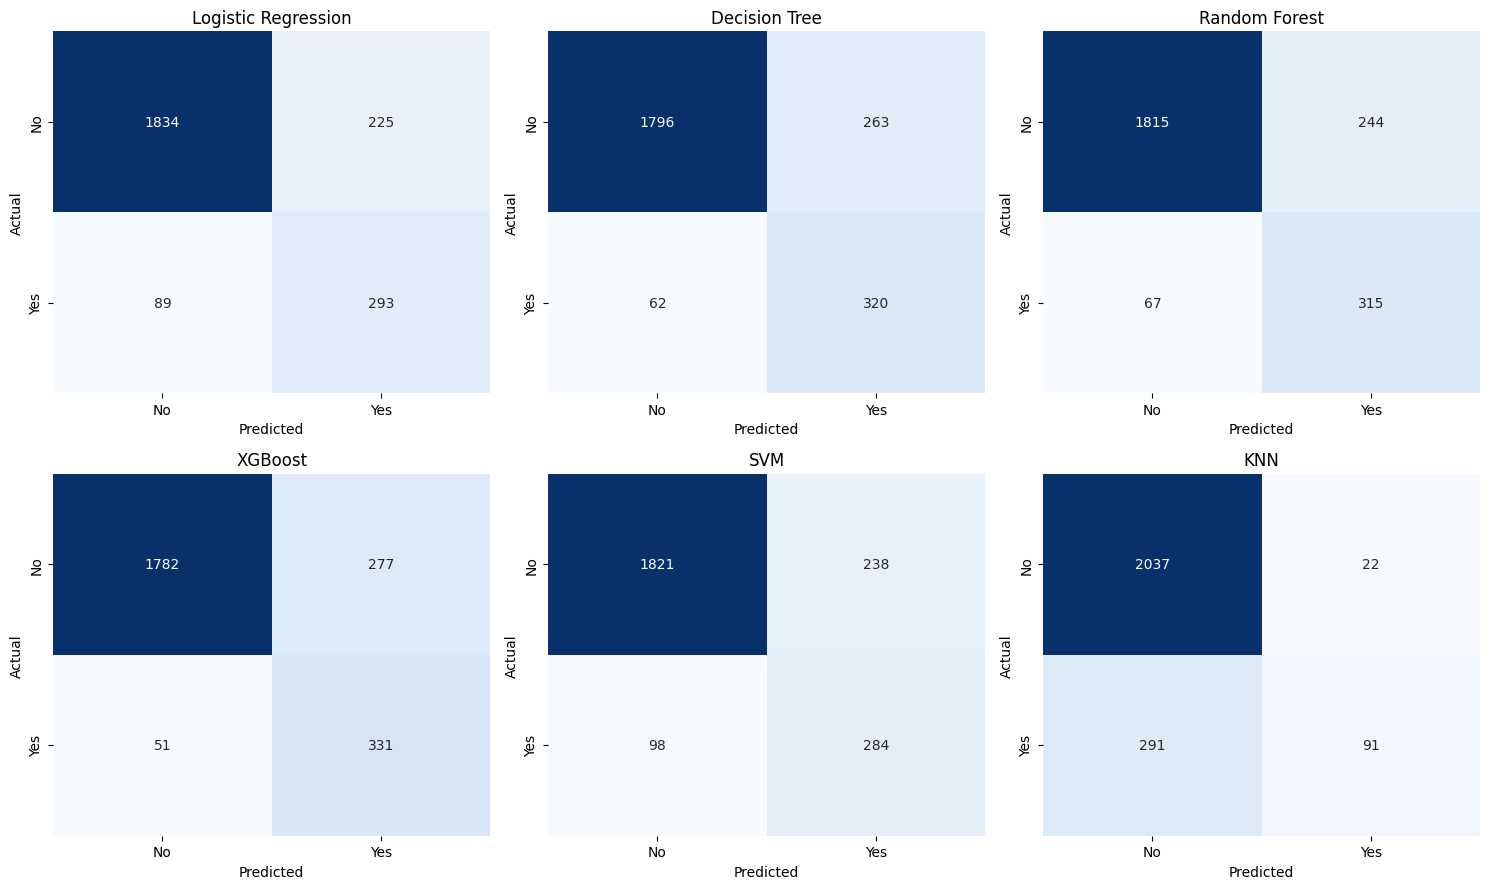

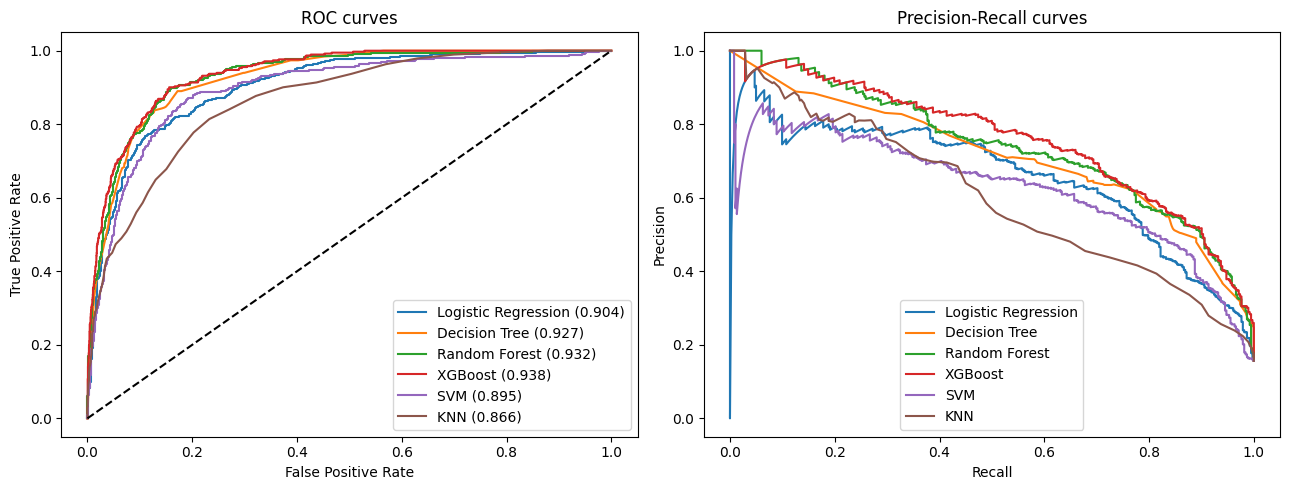

In [58]:
# confusion matrices
plt.figure(figsize=(15, 9))
for i, name in enumerate(models):
    plt.subplot(2, 3, i + 1)
    cm = confusion_matrix(y_test, test_pred[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ROC curve and Precision-Recall curve
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_score[name])
    plt.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, test_score[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend()

plt.subplot(1, 2, 2)
for name in models:
    p, r, _ = precision_recall_curve(y_test, test_score[name])
    plt.plot(r, p, label=name)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves")
plt.legend()
plt.tight_layout()
plt.show()

In [59]:
# How important is PageValues? Compare with and without it (5-fold CV)
model = models[best_name]
with_pv = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
without_pv = cross_val_score(model, X_train.drop("PageValues", axis=1), y_train, cv=cv, scoring="roc_auc")
print(f"{best_name} ROC-AUC with PageValues   : {with_pv.mean():.3f}")
print(f"{best_name} ROC-AUC without PageValues: {without_pv.mean():.3f}")

XGBoost ROC-AUC with PageValues   : 0.931
XGBoost ROC-AUC without PageValues: 0.776


PCA and K-Means Clustering

First 2 components explain only 30.2% of variance
13 components are needed for 90% variance (out of 19)


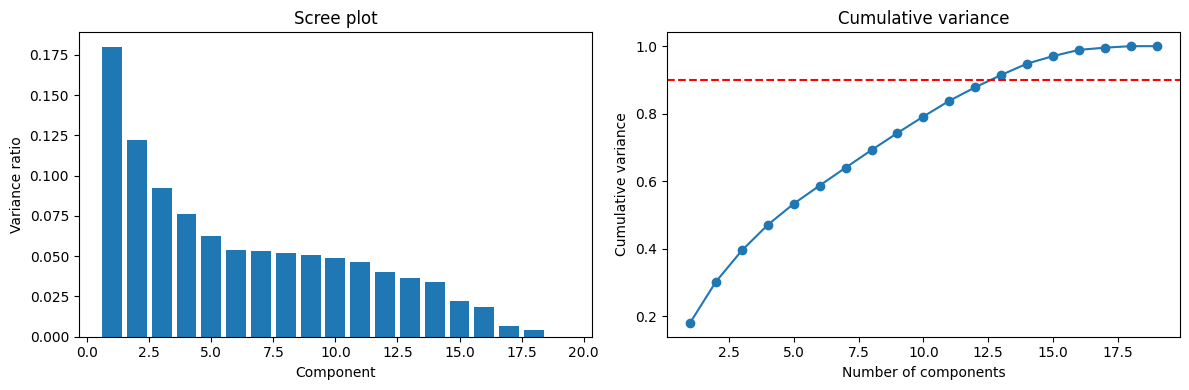

In [60]:
scaled = StandardScaler().fit_transform(X)
pca_all = PCA().fit(scaled)
cum_var = np.cumsum(pca_all.explained_variance_ratio_)
n_comp = np.argmax(cum_var >= 0.90) + 1
print(f"First 2 components explain only {cum_var[1]:.1%} of variance")
print(f"{n_comp} components are needed for 90% variance (out of {scaled.shape[1]})")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.bar(range(1, len(cum_var) + 1), pca_all.explained_variance_ratio_)
plt.xlabel("Component")
plt.ylabel("Variance ratio")
plt.title("Scree plot")
plt.subplot(1, 2, 2)
plt.plot(range(1, len(cum_var) + 1), cum_var, "o-")
plt.axhline(0.90, color="red", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance")
plt.title("Cumulative variance")
plt.tight_layout()
plt.show()

pca = PCA(n_components=n_comp, random_state=42)
X_pca = pca.fit_transform(scaled)

K = 2   inertia = 186315   silhouette = 0.2656
K = 3   inertia = 163492   silhouette = 0.2665
K = 4   inertia = 145733   silhouette = 0.2777
K = 5   inertia = 133299   silhouette = 0.2751
K = 6   inertia = 125111   silhouette = 0.1849
K = 7   inertia = 117133   silhouette = 0.1570
K = 8   inertia = 110843   silhouette = 0.1605


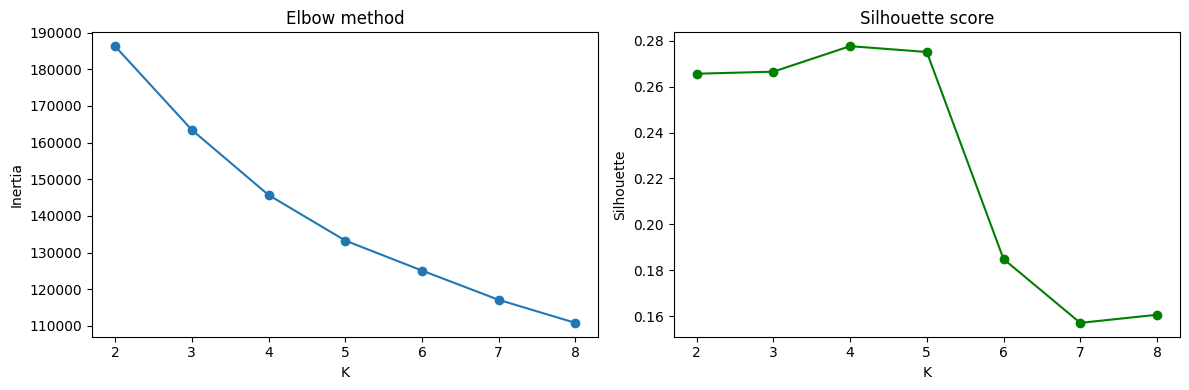

In [61]:
# find the best K using elbow and silhouette
k_values = range(2, 9)
inertia_list = []
sil_list = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pca)
    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_pca, km.labels_, sample_size=5000, random_state=42))
    print(f"K = {k}   inertia = {km.inertia_:.0f}   silhouette = {sil_list[-1]:.4f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(k_values, inertia_list, "o-")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.subplot(1, 2, 2)
plt.plot(k_values, sil_list, "o-", color="green")
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.title("Silhouette score")
plt.tight_layout()
plt.show()

Chosen K: 4
Silhouette score (full space): 0.2743


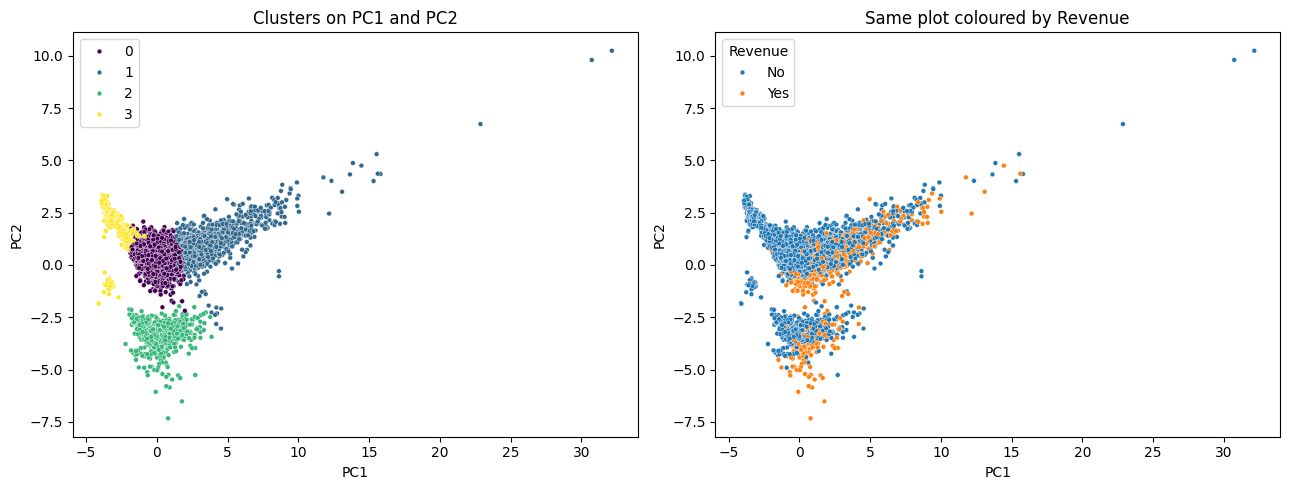

In [62]:
# K = 2 only separates "active" from "inactive", so we choose the best K from 3 to 8
best_k = 3 + int(np.argmax(sil_list[1:]))
print("Chosen K:", best_k)

kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit(X_pca)
clusters = kmeans.labels_
print("Silhouette score (full space):", round(silhouette_score(X_pca, clusters), 4))

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette="viridis", s=12)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters on PC1 and PC2")
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y.map({0: "No", 1: "Yes"}), s=12)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Same plot coloured by Revenue")
plt.tight_layout()
plt.show()

         Sessions  Share  Revenue  PageValues  ProductRelated  ProductRelated_Duration  Administrative  BounceRates  ExitRates  VisitorType_New_Visitor  Weekend
Cluster                                                                                                                                                         
0            8065  0.661    0.130       4.812          25.418                  935.021           1.623        0.011      0.035                    0.000    0.227
1            1484  0.122    0.282       9.507         102.565                 4073.367           7.431        0.006      0.020                    0.007    0.259
2            1723  0.141    0.253      11.432          17.837                  628.904           2.537        0.002      0.018                    0.961    0.276
3             933  0.076    0.006       0.000           3.404                   66.241           0.057        0.161      0.177                    0.030    0.178


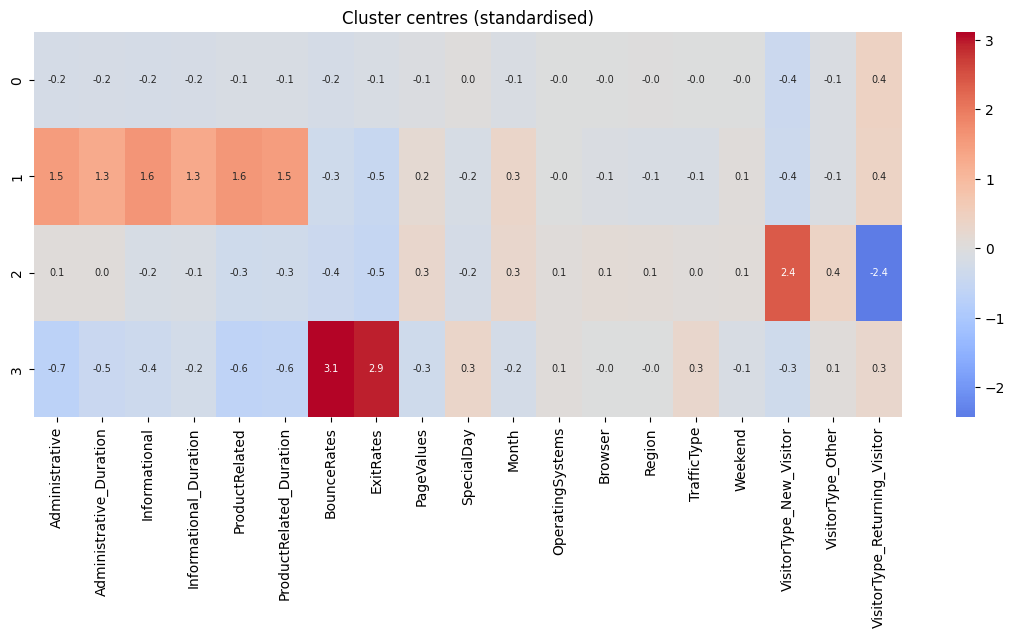

In [63]:
# describe each cluster
profile = data.copy()
profile["Cluster"] = clusters
summary = profile.groupby("Cluster")[["Revenue", "PageValues", "ProductRelated",
                                      "ProductRelated_Duration", "Administrative",
                                      "BounceRates", "ExitRates",
                                      "VisitorType_New_Visitor", "Weekend"]].mean()
summary.insert(0, "Sessions", profile["Cluster"].value_counts().sort_index())
summary.insert(1, "Share", summary["Sessions"] / len(profile))
print(summary.round(3).to_string())

# standardised centres
centres = pd.DataFrame(scaled, columns=X.columns).groupby(clusters).mean()
plt.figure(figsize=(14, 3 + 0.5 * best_k))
sns.heatmap(centres, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Cluster centres (standardised)")
plt.show()

Anomaly Detection with Isolation Forest


Total sessions : 12205
Normal         : 11594
Anomalous      : 611 (5.0%)
Buyer rate in anomalies: 27.2%   in normal sessions: 15.0%


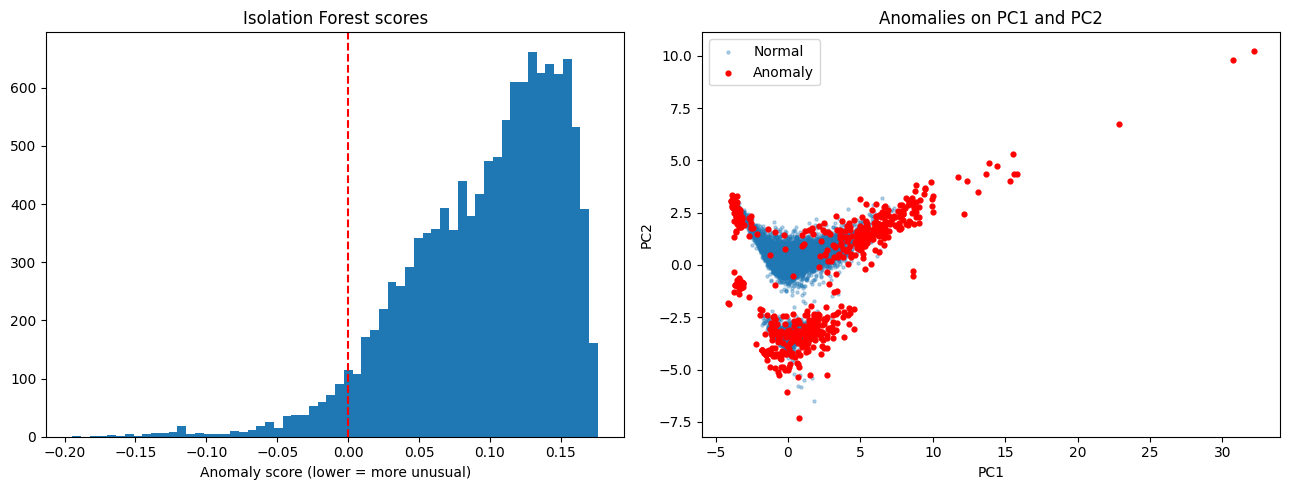

In [64]:
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=42)
iso.fit(scaled)
anomaly = iso.predict(scaled) == -1          # True = anomaly
anomaly_score = iso.decision_function(scaled)   # lower = more unusual

print("Total sessions :", len(data))
print("Normal         :", (~anomaly).sum())
print("Anomalous      :", anomaly.sum(), f"({anomaly.mean():.1%})")
print(f"Buyer rate in anomalies: {y[anomaly].mean():.1%}   in normal sessions: {y[~anomaly].mean():.1%}")

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.hist(anomaly_score, bins=60)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Anomaly score (lower = more unusual)")
plt.title("Isolation Forest scores")
plt.subplot(1, 2, 2)
plt.scatter(X_pca[~anomaly, 0], X_pca[~anomaly, 1], s=5, alpha=0.3, label="Normal")
plt.scatter(X_pca[anomaly, 0], X_pca[anomaly, 1], s=12, color="red", label="Anomaly")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Anomalies on PC1 and PC2")
plt.legend()
plt.tight_layout()
plt.show()

In [65]:
# why are they unusual?
cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated",
        "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "Revenue"]
compare = data.groupby(np.where(anomaly, "Anomalous", "Normal"))[cols].mean().T
print("Average values:")
print(compare.round(3).to_string())

print("\nShare of anomalies in each K-Means cluster:")
print(pd.Series(anomaly).groupby(clusters).mean().round(3).to_string())

print("\nVisitor type of anomalous sessions:")
print(raw_data.loc[anomaly, "VisitorType"].value_counts().to_string())

print("\nTop 10 most unusual sessions:")
top10 = np.argsort(anomaly_score)[:10]
show = ["Administrative", "Informational", "ProductRelated", "ProductRelated_Duration",
        "BounceRates", "ExitRates", "PageValues", "Revenue"]
print(data.iloc[top10][show].round(3).to_string())

Average values:
                         Anomalous    Normal
Administrative_Duration    284.568    70.952
Informational_Duration     222.453    24.938
ProductRelated              81.008    29.465
ProductRelated_Duration   3369.576  1093.015
BounceRates                  0.038     0.019
ExitRates                    0.049     0.041
PageValues                  15.294     5.457
Revenue                      0.272     0.150

Share of anomalies in each K-Means cluster:
0    0.002
1    0.173
2    0.136
3    0.115

Visitor type of anomalous sessions:
VisitorType
Returning_Visitor    325
New_Visitor          225
Other                 61

Top 10 most unusual sessions:
       Administrative  Informational  ProductRelated  ProductRelated_Duration  BounceRates  ExitRates  PageValues  Revenue
5074               17             24             705                43171.233        0.005      0.015       0.764        0
5594                0              4             222                 9630.210        0.05

##Feature Importance

Revenue               0     1  Buyer_Rate
VisitorType                              
New_Visitor        1271   422       0.249
Other                65    16       0.198
Returning_Visitor  8961  1470       0.141


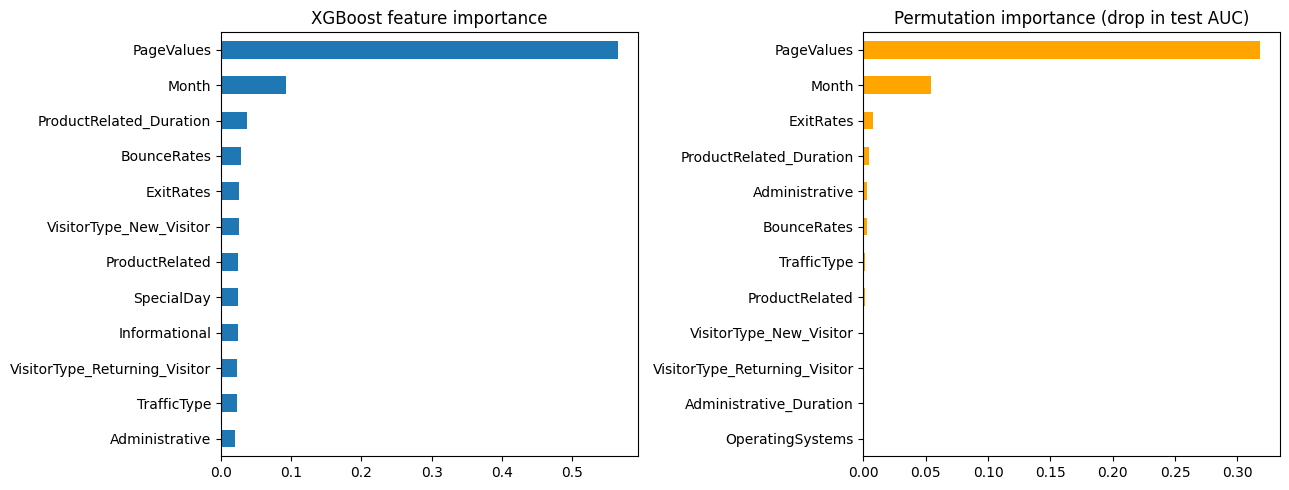

Top 5 features: ['PageValues', 'Month', 'ExitRates', 'ProductRelated_Duration', 'Administrative']


In [66]:
# Is VisitorType related to Revenue?
# Buyer rate by visitor type (no chi-square)
table_vt = pd.crosstab(raw_data["VisitorType"], data["Revenue"])
print(table_vt.assign(Buyer_Rate=(table_vt[1] / table_vt.sum(axis=1)).round(3)).to_string())

# Feature importance of XGBoost (trained on train data in Step 2)
xgb_model = models["XGBoost"]
importance = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)

perm = permutation_importance(xgb_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=42)
perm_importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
importance.head(12)[::-1].plot(kind="barh")
plt.title("XGBoost feature importance")
plt.subplot(1, 2, 2)
perm_importance.head(12)[::-1].plot(kind="barh", color="orange")
plt.title("Permutation importance (drop in test AUC)")
plt.tight_layout()
plt.show()
print("Top 5 features:", list(perm_importance.head(5).index))

##Predict on New Sessions
We train the best classifier and an Isolation Forest on all data, save them,and write one function that takes raw sessions (month name,visitor type text) and gives the purchase chance and an anomaly flag.

In [67]:
# final models (trained on all data)
import os
import joblib
final_model = models[best_name]
final_model.fit(X, y)
anomaly_model = make_pipeline(StandardScaler(),IsolationForest(n_estimators=300, contamination=0.05, random_state=42))
anomaly_model.fit(X)

os.makedirs("artifacts", exist_ok=True)
joblib.dump({"model": final_model, "anomaly_model": anomaly_model, "threshold": best_threshold,
             "columns": list(X.columns)}, "artifacts/shopper_model.joblib")
print("Saved: artifacts/shopper_model.joblib")

def prepare_raw(rows):
    # same preprocessing as Step 1, for raw data
    rows = rows.copy()
    rows["Weekend"] = rows["Weekend"].astype(int)
    rows["Month"] = rows["Month"].map(month_map)
    for v in visitor_types:
        rows["VisitorType_" + v] = (rows["VisitorType"] == v).astype(int)
    return rows[list(X.columns)]

def predict_sessions(rows):
    saved = joblib.load("artifacts/shopper_model.joblib")
    new_X = prepare_raw(rows)
    prob = saved["model"].predict_proba(new_X)[:, 1]
    flag = saved["anomaly_model"].predict(new_X)
    result = pd.DataFrame()
    result["Purchase_Chance_%"] = (prob * 100).round(2)
    result["Prediction"] = np.where(prob >= saved["threshold"], "Buyer", "Non-Buyer")
    result["Status"] = np.where(flag == -1,     "Unusual:check manually", "Normal")
    return result

# test with 3 real sessions and 1 new session
first_buyer = raw_data.index[raw_data["Revenue"]][0]
most_unusual = int(np.argmin(anomaly_score))
sample = raw_data.drop("Revenue", axis=1).iloc[[0, first_buyer, most_unusual]]

new_session = pd.DataFrame([{
    "Administrative": 3, "Administrative_Duration": 120.0, "Informational": 1,
    "Informational_Duration": 40.0, "ProductRelated": 35, "ProductRelated_Duration": 1500.0,
    "BounceRates": 0.01, "ExitRates": 0.02, "PageValues": 25.0, "SpecialDay": 0.0,
    "Month": "Nov", "OperatingSystems": 2, "Browser": 2, "Region": 1, "TrafficType": 2,
    "VisitorType": "Returning_Visitor", "Weekend": False}])

sample = pd.concat([sample, new_session], ignore_index=True)
output = predict_sessions(sample)
output.insert(0, "Session", ["Row 0", "First buyer", "Most unusual", "New Nov session"])
print(output.to_string(index=False))

Saved: artifacts/shopper_model.joblib
        Session  Purchase_Chance_% Prediction                 Status
          Row 0           1.120000  Non-Buyer                 Normal
    First buyer          91.639999      Buyer                 Normal
   Most unusual          36.130001  Non-Buyer Unusual:check manually
New Nov session          85.000000      Buyer                 Normal


## Final Summary

In [68]:
print("Sessions used          :", len(data), "(duplicates removed)")
print("Best classifier        :", best_name)
print(f"Test ROC-AUC           :{results.loc[best_name, 'ROC-AUC']:.3f}")
print(f"Test F1 (tuned threshold): {f1_score(y_test, new_pred):.3f}")
print(f"PCA components for 90% : {n_comp}   K-Means K = {best_k}")
print(f"Anomalies found        : {anomaly.sum()} ({anomaly.mean():.1%})")
print("Top features           :", list(perm_importance.head().index))

Sessions used          : 12205 (duplicates removed)
Best classifier        : XGBoost
Test ROC-AUC           :0.938
Test F1 (tuned threshold): 0.689
PCA components for 90% : 13   K-Means K = 4
Anomalies found        : 611 (5.0%)
Top features           : ['PageValues', 'Month', 'ExitRates', 'ProductRelated_Duration', 'Administrative']
